Customer Dataset:
    Customer  Annual_Spending  Visits_Per_Month
0          1            10000                 2
1          2            12000                 1
2          3            14000                 3
3          4            13000                 2
4          5            15000                 2
5          6            28000                 4
6          7            32000                 5
7          8            35000                 6
8          9            33000                 5
9         10            30000                 4
10        11            55000                 8
11        12            60000                 9
12        13            64000                10
13        14            58000                 9
14        15            62000                11

K-Means Clustering:
    Customer  Annual_Spending  Visits_Per_Month  Cluster
0          1            10000                 2        2
1          2            12000                 1        2
2          3          

C:\Users\manoj\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


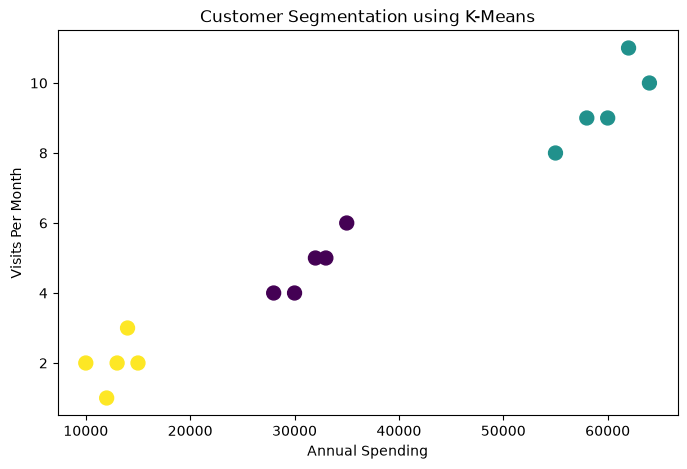


Average Spending of Each Cluster:
Cluster
0    31600.0
1    59800.0
2    12800.0
Name: Annual_Spending, dtype: float64

Elbow and Silhouette Score Comparison:
   K Value   Inertia  Silhouette Score
0        2  5.542387          0.698836
1        3  1.247359          0.736524
2        4  0.752948          0.659086

Silhouette Scores:
K=2: 0.6988361359184785
K=3: 0.7365242722195832
K=4: 0.6590860598739645


C:\Users\manoj\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\manoj\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\manoj\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


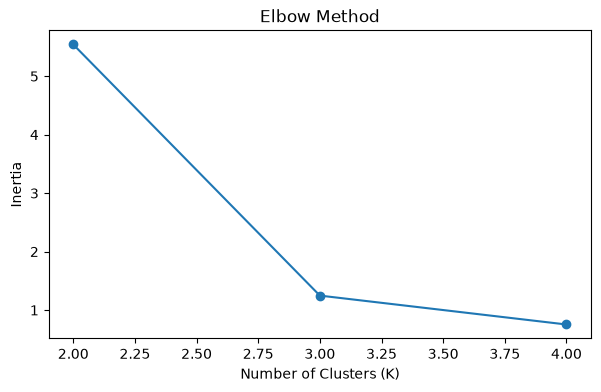

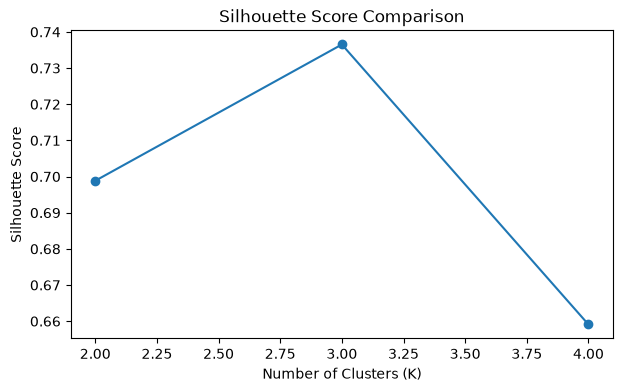


DBSCAN Clustering:
    Customer  DBSCAN_Cluster
0          1               0
1          2               0
2          3               0
3          4               0
4          5               0
5          6               0
6          7               0
7          8               0
8          9               0
9         10               0
10        11               1
11        12               1
12        13               1
13        14               1
14        15               1


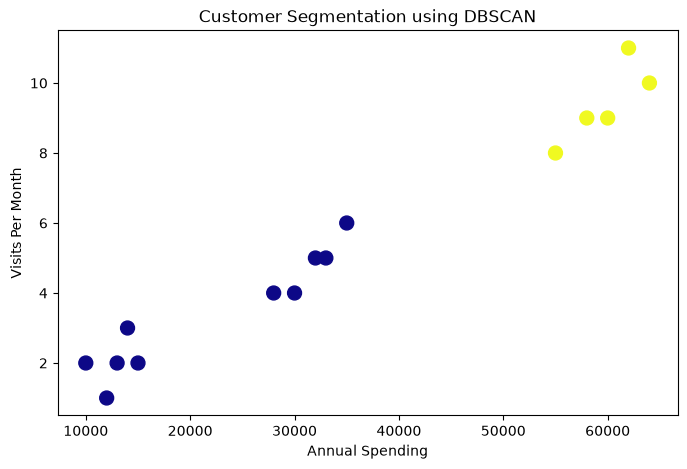


Customer Segment Descriptions:

Cluster 0
Average Spending: 31600.0
Average Visits: 4.8

Cluster 1
Average Spending: 59800.0
Average Visits: 9.4

Cluster 2
Average Spending: 12800.0
Average Visits: 2.0

-1 label in DBSCAN represents noise or outliers.


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
data = {
    'Customer': range(1, 16),
    'Annual_Spending': [
        10000, 12000, 14000, 13000, 15000,
        28000, 32000, 35000, 33000, 30000,
        55000, 60000, 64000, 58000, 62000
    ],
    'Visits_Per_Month': [
        2, 1, 3, 2, 2,
        4, 5, 6, 5, 4,
        8, 9, 10, 9, 11
    ]
}

df = pd.DataFrame(data)

print("Customer Dataset:")
print(df)



X = df[['Annual_Spending', 'Visits_Per_Month']]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)


kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

df['Cluster'] = kmeans.fit_predict(X_scaled)

print("\nK-Means Clustering:")
print(df)

plt.figure(figsize=(8, 5))

plt.scatter(
    df['Annual_Spending'],
    df['Visits_Per_Month'],
    c=df['Cluster'],
    cmap='viridis',
    s=100
)

plt.xlabel('Annual Spending')
plt.ylabel('Visits Per Month')
plt.title('Customer Segmentation using K-Means')
plt.show()



print("\nAverage Spending of Each Cluster:")
print(df.groupby('Cluster')['Annual_Spending'].mean())



inertia = []
silhouette = []

for k in range(2, 5):

    model = KMeans(n_clusters=k, random_state=42, n_init=10)

    labels = model.fit_predict(X_scaled)

    inertia.append(model.inertia_)

    silhouette.append(silhouette_score(X_scaled, labels))

results = pd.DataFrame({
    'K Value': [2, 3, 4],
    'Inertia': inertia,
    'Silhouette Score': silhouette
})

print("\nElbow and Silhouette Score Comparison:")
print(results)



print("\nSilhouette Scores:")
print("K=2:", silhouette[0])
print("K=3:", silhouette[1])
print("K=4:", silhouette[2])



plt.figure(figsize=(7, 4))
plt.plot([2, 3, 4], inertia, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method')
plt.show()



plt.figure(figsize=(7, 4))
plt.plot([2, 3, 4], silhouette, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Silhouette Score')
plt.title('Silhouette Score Comparison')
plt.show()



dbscan = DBSCAN(eps=0.8, min_samples=2)

df['DBSCAN_Cluster'] = dbscan.fit_predict(X_scaled)

print("\nDBSCAN Clustering:")
print(df[['Customer', 'DBSCAN_Cluster']])



plt.figure(figsize=(8, 5))

plt.scatter(
    df['Annual_Spending'],
    df['Visits_Per_Month'],
    c=df['DBSCAN_Cluster'],
    cmap='plasma',
    s=100
)

plt.xlabel('Annual Spending')
plt.ylabel('Visits Per Month')
plt.title('Customer Segmentation using DBSCAN')
plt.show()



print("\nCustomer Segment Descriptions:")

for cluster in sorted(df['Cluster'].unique()):
    group = df[df['Cluster'] == cluster]

    print("\nCluster", cluster)
    print("Average Spending:", group['Annual_Spending'].mean())
    print("Average Visits:", group['Visits_Per_Month'].mean())

print("\n-1 label in DBSCAN represents noise or outliers.")
